# NB2 · The Manual
**From Forms to Agents · Lecture 2 · Vizuara · Dr. Rajat Dandekar**

The form did nine jobs. This notebook takes over **job 4: explaining the rules**.

Before: a 400-page PDF behind the Help button that nobody reads, and Suresh, who remembers that food-contact parts need a certificate.
After: answers with the clause attached. Stock and budget still come from the ERP, never from a document.

You will build, in order: a chunker, BM25, embeddings, hybrid search with a reranker, citations you can check,
permissions and freshness, an LLM Wiki, and one tool, `search_policy`. At the end, scenario 1 passes.

Everything here is fictional: Bahi ERP 7.2, Rasoi Steel Works and its people.
Replay mode plays back our recorded model calls, so no key is needed.

In [1]:
# Setup: install the Bahi sandbox and its recorded model replies. Runs in about a minute on Colab.
# REPLAY mode (the default when you have no key) plays back our recorded model calls, so every cell runs
# without an API key and shows the numbers from our own run. To call a model live, set a key below.
import os, sys, subprocess
COURSE_REPO = "https://github.com/RajatDandekar/agents-for-enterprises"   # course code (Bahi sandbox + reference agent)
try:
    import bahi  # already available (local checkout or Modal)
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"bahi-erp[all] @ git+{COURSE_REPO}.git#subdirectory=bahi"], check=True)
    import bahi
# os.environ["GEMINI_API_KEY"] = "..."        # optional: your own key, to run live
# os.environ["OPENROUTER_API_KEY"] = "..."    # optional: GPT, Claude, Llama ... via OpenRouter
os.environ.setdefault("BAHI_LLM_MODE", "auto")  # auto = replay what was recorded, call live only for new requests
print("Bahi", bahi.__version__, "· model mode:", os.environ["BAHI_LLM_MODE"])

Bahi 0.1.0 · model mode: replay


In [2]:
import json, os, pathlib, re, math, urllib.request
import pandas as pd
import matplotlib.pyplot as plt
from bahi import ERP
from bahi.llm import LLM
from bahi.scenarios import SCENARIOS, run_scenario, scorecard
from bahi.agent import retrieval as R

MODEL = "gemini:gemini-3.8-flash"
pd.set_option("display.max_colwidth", 120)


def load_log(name):
    """Our experiment logs: from the course folder if it is here, else from the course repository."""
    for p in [pathlib.Path("experiments/logs") / name, pathlib.Path("lectures/L2-the-manual/experiments/logs") / name]:
        if p.exists():
            return json.loads(p.read_text())
    url = f"https://raw.githubusercontent.com/RajatDandekar/agents-for-enterprises/main/lectures/L2-the-manual/experiments/logs/{name}"
    return json.loads(urllib.request.urlopen(url).read())

## 1. The failure: scenario 1 with Lecture 1's agent
Kavita asks a rule question. The naive agent has 38 raw services and no documents. Here is what it did in our run
(replayed from cassette `L2_naive`).

In [3]:
from bahi.agent.naive import NaiveAgent
naive_llm = LLM(MODEL, cassette="L2_naive")
res = run_scenario(lambda erp, user: NaiveAgent(erp, user, llm=naive_llm), SCENARIOS[0])
t = res.turns[0]
print("KAVITA:", t["user"])
print("\nAGENT: ", t["agent"])
print("\nservices it called:", t["services"])
print("\npassed:", res.passed, "| notes:", res.notes, "| tokens:", res.tokens_in + res.tokens_out)

KAVITA: Can we buy the 5-litre gaskets from a supplier that doesn't have a food-grade certificate? Their price is much better.

AGENT:  **No, we cannot.** 

Here is why:

1. **Mandatory Food-Contact Compliance:** 
   The 5-litre silicone gasket (`GSK-SIL-05L`) is flagged in the system master as **`food_contact: 1`**. Because gaskets come into direct contact with food and steam in pressure cookers, having valid food-grade certification (e.g., FSSAI / accredited lab certification) is a non-negotiable regulatory and safety requirement.

2. **ERP Validation Rules:** 
   Bahi ERP enforces that POs for items with `food_contact: 1` cannot be approved or released without a valid, non-expired `FOOD-GRADE` certificate registered under the supplier's profile.

3. **Current Approved Supplier:** 
   Our current supplier, **Deccan Polymers (`DP-RJK-0042`)**, holds an active food-grade certificate (`FSSAI-LAB/DP/2026/118`) valid through **31 March 2027**.

---

### How to proceed if the new supplier 

The rule exists. It is Purchase Policy §6.2. But it lives in a document, and the model has never seen the
document: it is private, it was written after the model's training, and the only way in is the context window.

## 2. The corpus
Seven documents Kavita may read, plus one she may not. Each has front-matter: an id, a version, the date it takes
effect, who may read it, and (for amendments) which clause it changes.

In [4]:
docs = R.load_corpus()
rows = []
for d in docs:
    rows.append({"doc_id": d.doc_id, "title": d.title, "version": d.version, "effective": d.effective,
                 "audience": d.audience, "amends": ", ".join(d.amends), "words": len(d.body.split()),
                 "tokens": R.count_tokens(d.body)})
corpus = pd.DataFrame(rows).set_index("doc_id")
corpus

,title,version,effective,audience,amends,words,tokens
doc_id,,,,,,,
AMD-PUR-2026-03,Amendment 3 to the Purchase Policy,1.0,2026-12-01,all purchase staff,POL-PUR-001 §3.3,149,305
AMD-SUP-2026-02,Amendment 2 to the Supplier Policy,1.0,2026-09-01,all purchase staff,POL-SUP-003 §4.4,219,349
POL-APR-002,Approval Matrix for Purchasing,3.0,2026-04-01,all purchase staff,,483,812
MAN-DD-72,"Bahi ERP 7.2 Data Dictionary, Purchasing",7.2.3,2025-01-15,all Bahi users,,568,1211
HR-CONF-007,Salary Bands 2026-27 (Confidential),1.0,2026-04-01,hr only,,158,332
POL-PUR-001,Purchase Policy,4.1,2026-04-01,all purchase staff,,541,792
POL-SUP-003,Supplier Policy,2.3,2026-04-01,all purchase staff,,892,1273
MAN-PUR-72,"Bahi ERP 7.2 User Manual, Purchasing and Inventory Enquiry",7.2.3,2025-01-15,all Bahi users,,5530,8331


In [5]:
print("All of it:", corpus.tokens.sum(), "tokens. The user manual alone:", corpus.loc["MAN-PUR-72", "tokens"])

All of it: 13405 tokens. The user manual alone: 8331


## 3. Chunking: what a good chunk looks like
We cannot hand the model everything every turn (Section 9 counts what that costs). So we cut the documents into
pieces and fetch the right pieces. A good chunk is **one rule, whole, with its heading attached**, and its id is its
citation: `POL-PUR-001 §6.2`.

### Exercise 1
Write `my_chunker(doc)`: start a new chunk at every `## N. Heading`, every `### N.M Heading`, and every line that
starts with a clause number `N.M ` inside section N. Keep the heading with each chunk.

In [6]:
SOLUTION = True   # set to False to write your own


def my_chunker(doc):
    # TODO (exercise 1): return a list of (section, heading, text)
    if not SOLUTION:
        raise NotImplementedError
    out, h2, cur = [], ("", ""), None
    for line in doc.body.splitlines():
        if line.startswith("# "):
            continue
        m2 = re.match(r"^##\s+(\d+)\.\s+(.*)$", line)
        m3 = re.match(r"^###\s+(\d+\.\d+)\s+(.*)$", line)
        mc = re.match(r"^(\d+\.\d+)\s+\S", line)
        if m2:
            if cur: out.append(cur)
            h2 = (m2[1], m2[2]); cur = [m2[1], f"{m2[1]}. {m2[2]}", ""]
        elif m3:
            if cur: out.append(cur)
            cur = [m3[1], f"{h2[0]}. {h2[1]} › {m3[1]} {m3[2]}", ""]
        elif mc and mc[1].split(".")[0] == h2[0]:
            if cur: out.append(cur)
            cur = [mc[1], f"{h2[0]}. {h2[1]}", line]
        elif cur is not None:
            cur[2] += "\n" + line
    if cur: out.append(cur)
    return [tuple(c) for c in out if c[2].strip()]


pp = next(d for d in docs if d.doc_id == "POL-PUR-001")
mine = my_chunker(pp)
lib = R.chunk_by_section(pp)
print(len(mine), "chunks (yours) ·", len(lib), "chunks (library) · same ids:", [m[0] for m in mine] == [c.section for c in lib])
print(next(c for c in lib if c.section == "6.2").render())

22 chunks (yours) · 22 chunks (library) · same ids: True
[POL-PUR-001 §6.2] Purchase Policy v4.1, effective 2026-04-01 › 6. Supplier qualification
6.2 **Parts that come into contact with food** (gaskets, lids, body blanks and any other item marked food-contact in the item master) may be bought only from a supplier holding a **valid food-grade certificate** on file in Bahi. The certificate must be uploaded and checked **before the first order** is placed. An expired certificate counts as no certificate.


Now the naive way: fixed windows of 120 words. Look at what lands in the window that holds §6.2.

In [7]:
for c in R.chunk_fixed(pp, size=120, overlap=20):
    if "food-grade" in c.text:
        print(c.id, "→", c.text[:400], "...\n")

POL-PUR-001 w300-420 → may be placed only with suppliers that are **active** in the supplier master. 6.2 **Parts that come into contact with food** (gaskets, lids, body blanks and any other item marked food-contact in the item master) may be bought only from a supplier holding a **valid food-grade certificate** on file in Bahi. The certificate must be uploaded and checked **before the first order** is placed. An expired ...



The window starts mid-clause, carries pieces of §5 and §6.1, and has no id you could cite. Section chunks fix all three.

## 4. Keyword search: BM25
BM25 scores a chunk by the rare words it shares with the question, with diminishing returns for repeats and a
penalty for long chunks:

score(q, d) = Σ over words t of  idf(t) · tf(t,d)·(k1+1) / (tf(t,d) + k1·(1 − b + b·|d|/avgdl))

### Exercise 2
Fill in `idf` and `bm25_score`. The tokenizer keeps codes like `ERR-PO-0412` and `6.2` whole.

In [8]:
ret = R.Retriever("KJOSHI")                       # Kavita's index: everything she may read, as of 26 Oct 2026
toks = [R.tokenize(c.context_text) for c in ret.chunks]
N = len(toks); avgdl = sum(map(len, toks)) / N
df = {}
for d in toks:
    for t in set(d):
        df[t] = df.get(t, 0) + 1


def idf(t):
    # TODO (exercise 2a)
    return math.log(1 + (N - df.get(t, 0) + 0.5) / (df.get(t, 0) + 0.5))


def bm25_score(q, d, k1=1.2, b=0.75):
    # TODO (exercise 2b)
    s = 0.0
    for t in q:
        f = d.count(t)
        if f:
            s += idf(t) * f * (k1 + 1) / (f + k1 * (1 - b + b * len(d) / avgdl))
    return s


q1 = SCENARIOS[0].ask
qt = R.tokenize(q1)
mine = sorted(range(N), key=lambda i: -bm25_score(qt, toks[i]))[:5]
print("question tokens:", qt)
pd.DataFrame([{"rank": r + 1, "chunk": ret.chunks[i].id, "yours": round(bm25_score(qt, toks[i]), 3),
               "library": round(ret.bm25.scores(qt)[i], 3), "words that scored": ret.bm25.term_scores(qt, i)}
              for r, i in enumerate(mine)])

question tokens: ['buy', '5-litre', 'litre', 'gasket', 'supplier', 'doesn', 't', 'food-grade', 'food', 'grade', 'certificate', 'price', 'much', 'better']


,rank,chunk,yours,library,words that scored
0,1,POL-SUP-003 §4.2,21.436,21.436,"{'supplier': 0.9052834131628891, 'food-grade': 3.1815261634869882, 'food': 3.8174516117341497, 'grade': 4.3259815792..."
1,2,POL-SUP-003 §4.1,21.219,21.219,"{'gasket': 3.4109694670960984, 'supplier': 1.180716910800383, 'food-grade': 4.149509080541435, 'food': 4.53699787195..."
2,3,POL-SUP-003 §4.3,17.902,17.902,"{'supplier': 1.252233312971451, 'food-grade': 4.400846177098588, 'food': 3.8835156886245925, 'grade': 4.400846177098..."
3,4,POL-PUR-001 §6.2,17.216,17.216,"{'gasket': 3.019843304720594, 'supplier': 1.083479014585883, 'food-grade': 2.650883906519151, 'food': 3.932188203639..."
4,5,POL-SUP-003 §4.5,15.906,15.906,"{'supplier': 1.252233312971451, 'food-grade': 3.2631772176602247, 'food': 3.8835156886245925, 'grade': 3.26317721766..."


§6.2 is only fourth. The top chunk, Supplier Policy §4.2, wins partly on the word **"better"** ("grade 304 or
better"), which Kavita used in a different sense. Keywords match spelling, not meaning.

## 5. Embeddings: meaning as a direction
An embedding model turns a text into 384 numbers. Texts that mean similar things point in similar directions, so
we compare them with the cosine of the angle. We use `BAAI/bge-small-en-v1.5` on the CPU (no key; same numbers
every run; vectors cached and rounded so replay ranks exactly as our run did).

### Exercise 3
Write `cos(a, b)` and rank Kavita's chunks by it.

In [9]:
def cos(a, b):
    # TODO (exercise 3)
    return sum(x * y for x, y in zip(a, b)) / (math.sqrt(sum(x * x for x in a)) * math.sqrt(sum(y * y for y in b)))


qv = ret.embedder.embed([q1], kind="query")[0]
print("one vector:", len(qv), "numbers, starting", qv[:5])
top = sorted(range(N), key=lambda i: -cos(qv, ret.vecs[i]))[:5]
pd.DataFrame([{"rank": r + 1, "chunk": ret.chunks[i].id, "cosine": round(cos(qv, ret.vecs[i]), 4)} for r, i in enumerate(top)])

one vector: 384 numbers, starting [0.02017, -0.00187, 0.01834, -0.00179, 0.00665]


,rank,chunk,cosine
0,1,POL-PUR-001 §6.2,0.7595
1,2,POL-SUP-003 §4.1,0.7101
2,3,AMD-SUP-2026-02 §2.1,0.6957
3,4,MAN-PUR-72 §3.2,0.6872
4,5,POL-APR-002 §5.1,0.6782


Now §6.2 is first. Here is the whole corpus, every chunk's vector squeezed to two dimensions (PCA), with Kavita's
question dropped in.

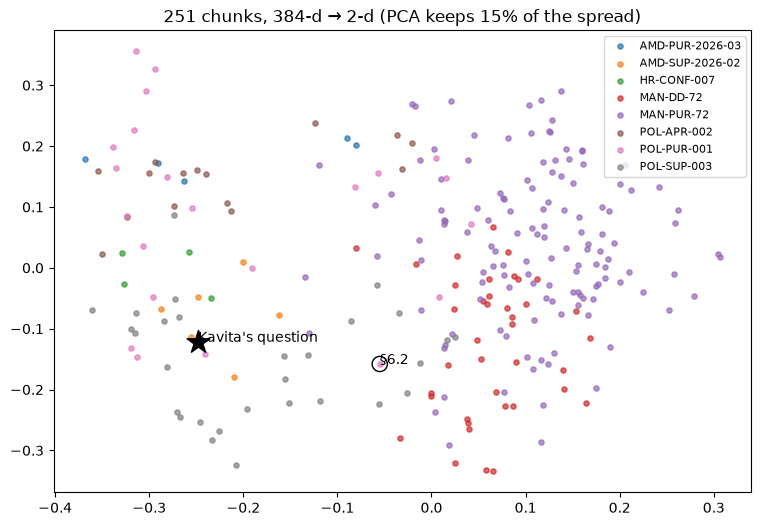

In [10]:
import numpy as np
allr = R.Retriever("KJOSHI", permissions=False)
X = np.array(allr.vecs); mu = X.mean(0)
U, S, Vt = np.linalg.svd(X - mu, full_matrices=False)
P = (X - mu) @ Vt[:2].T
qp = (np.array(qv) - mu) @ Vt[:2].T
fig, ax = plt.subplots(figsize=(9, 6))
for doc_id in sorted({c.doc_id for c in allr.chunks}):
    idx = [i for i, c in enumerate(allr.chunks) if c.doc_id == doc_id]
    ax.scatter(P[idx, 0], P[idx, 1], s=14, label=doc_id, alpha=.7)
i62 = next(i for i, c in enumerate(allr.chunks) if c.id == "POL-PUR-001 §6.2")
ax.scatter(*P[i62], s=120, facecolors="none", edgecolors="k"); ax.annotate("§6.2", P[i62])
ax.scatter(*qp, marker="*", s=300, c="k"); ax.annotate("Kavita's question", qp)
ax.legend(fontsize=8); ax.set_title(f"{len(X)} chunks, 384-d → 2-d (PCA keeps {100*(S[:2]**2).sum()/(S**2).sum():.0f}% of the spread)")
plt.show()

Two dimensions throw most of the 384 away, so read the picture loosely: the cosine above is the real measure.
Embeddings have their own blind spot: codes. Ask about `ERR-PO-0412`:

In [11]:
qe = "What does error ERR-PO-0412 mean and how do I fix it?"
for mode in ["bm25", "vector", "hybrid", "hybrid+rerank"]:
    ids = [h.chunk.id for h in ret.search(qe, k=10, mode=mode)]
    print(f"{mode:14s} rank of MAN-PUR-72 §17.2:", ids.index("MAN-PUR-72 §17.2") + 1 if "MAN-PUR-72 §17.2" in ids else "not in top 10")

bm25           rank of MAN-PUR-72 §17.2: 2
vector         rank of MAN-PUR-72 §17.2: not in top 10
hybrid         rank of MAN-PUR-72 §17.2: not in top 10
hybrid+rerank  rank of MAN-PUR-72 §17.2: 1


## 6. Hybrid search and reranking
Each method misses something the other catches. **Reciprocal rank fusion** combines them by rank: each list gives
an item 1/(60 + rank). A **cross-encoder reranker** then reads the question and each of the top 20 candidates
*together* and scores the pair: slower, so it only sees the shortlist.

### Exercise 4
Write `my_rrf(lists)`.

In [12]:
def my_rrf(lists, k=60):
    # TODO (exercise 4)
    out = {}
    for lst in lists:
        for rank, item in enumerate(lst, 1):
            out[item] = out.get(item, 0) + 1 / (k + rank)
    return out


b = [ret.chunks[i].id for i, _ in ret.bm25_rank(q1)[:20]]
v = [ret.chunks[i].id for i, _ in ret.vector_rank(q1)[:20]]
f = my_rrf([b, v])
fused = sorted(f, key=lambda x: -f[x])[:5]
rr = ret.search(q1, k=5)
pd.DataFrame({"BM25": b[:5], "embeddings": v[:5], "hybrid (RRF)": fused,
              "hybrid + rerank": [h.chunk.id for h in rr], "rerank score": [h.score for h in rr]})

,BM25,embeddings,hybrid (RRF),hybrid + rerank,rerank score
0,POL-SUP-003 §4.2,POL-PUR-001 §6.2,POL-SUP-003 §4.1,POL-PUR-001 §6.2,1.6087
1,POL-SUP-003 §4.1,POL-SUP-003 §4.1,POL-PUR-001 §6.2,POL-SUP-003 §4.1,-0.5975
2,POL-SUP-003 §4.3,AMD-SUP-2026-02 §2.1,POL-SUP-003 §4.3,POL-SUP-003 §4.5,-2.0789
3,POL-PUR-001 §6.2,MAN-PUR-72 §3.2,POL-SUP-003 §4.2,POL-SUP-003 §4.7,-2.1155
4,POL-SUP-003 §4.5,POL-APR-002 §5.1,POL-SUP-003 §4.5,POL-SUP-003 §4.3,-3.1552


Over all 33 questions in our test set that have a gold clause (no model calls, just ranking):

In [13]:
ev = load_log("retrieval_eval.json")
pd.DataFrame(ev["summary"]).T

,n,recall@1,recall@3,recall@5,recall@10,mrr
bm25,33.0,0.727,0.909,0.939,1.00,0.833
vector,33.0,0.727,0.939,0.970,0.97,0.834
hybrid,33.0,0.788,0.939,0.970,0.97,0.865
hybrid+rerank,33.0,0.848,0.970,1.000,1.00,0.917


## 7. Permissions and freshness
**Permissions.** Kavita is PUR-EXEC. HR's salary page (HR-CONF-007) is for HR only. The filter runs *before*
ranking: documents she may not read are not in her index at all, so no prompt can pull them out.

In [14]:
qh = "What is the salary band for a purchase executive?"
print("Kavita's index:   ", [h.chunk.id for h in ret.search(qh, k=4)])
print("no filter (wrong):", [h.chunk.id for h in allr.search(qh, k=4)])

Kavita's index:    ['POL-APR-002 §5.1', 'POL-APR-002 §3.1', 'POL-SUP-003 §3.1', 'MAN-PUR-72 §1.1']
no filter (wrong): ['HR-CONF-007 §2.1', 'HR-CONF-007 §2.2', 'POL-APR-002 §5.1', 'HR-CONF-007 §1.1']


**Freshness.** Amendment AMD-SUP-2026-02 (in force from 1 Sep 2026) replaces Supplier Policy §4.4.
AMD-PUR-2026-03 changes the direct-order limit, but only from 1 Dec 2026. The retriever reads `effective` against
Bahi's date (26 Oct 2026): a replaced clause leaves the index; a future one is labelled.

In [15]:
chunks = [c for d in docs for c in R.chunk_by_section(d)]
R.apply_freshness(chunks, docs, as_of="2026-10-26")
pd.DataFrame([{"clause": c.id, "status": c.status} for c in chunks if c.status != "in force"])

,clause,status
0,AMD-PUR-2026-03 §1.1,not yet in force: applies from 2026-12-01
1,AMD-PUR-2026-03 §1.2,not yet in force: applies from 2026-12-01
2,AMD-PUR-2026-03 §2.1,not yet in force: applies from 2026-12-01
3,AMD-PUR-2026-03 §3.1,not yet in force: applies from 2026-12-01
4,AMD-PUR-2026-03 §3.2,not yet in force: applies from 2026-12-01
5,POL-PUR-001 §3.3,in force until 2026-11-30; replaced from 2026-12-01 by AMD-PUR-2026-03 §1.1
6,POL-SUP-003 §4.4,replaced from 2026-09-01 by AMD-SUP-2026-02 §1.1; do not apply this text


## 8. Citations you can check
A citation is only worth something if code can check it: does the clause exist, and was it actually in front of
the model when it answered?

### Exercise 5
Write `my_check(answer, context_ids)` returning the cited ids that do not exist in the corpus.

In [16]:
ALL = R.corpus_ids(docs)


def my_check(answer, context_ids):
    # TODO (exercise 5)
    cites = [f"{d} §{s}" for d, s in re.findall(r"((?:POL|MAN|AMD|HR)-[A-Z0-9]+(?:-[A-Z0-9]+)*)\s*§\s*(\d+(?:\.\d+)?)", answer)]
    return [c for c in cites if c not in ALL]


demo = "No. Food-contact parts need a certificate [POL-PUR-001 §6.2]; see also [POL-PUR-001 §6.9]."
print("invented:", my_check(demo, ["POL-PUR-001 §6.2"]))
print(R.check_citations(demo, ["POL-PUR-001 §6.2"], ALL))

invented: ['POL-PUR-001 §6.9']
{'cites': ['POL-PUR-001 §6.2', 'POL-PUR-001 §6.9'], 'exist': ['POL-PUR-001 §6.2'], 'invented': ['POL-PUR-001 §6.9'], 'grounded': ['POL-PUR-001 §6.2'], 'ungrounded': []}


## 9. RAG: retrieve, then answer
The retrieved clauses go into the prompt, each headed by its citation. One model call.

In [17]:
answer_llm = LLM(MODEL, cassette="L2_answers", max_tokens=4096)
ps_eval = R.PolicySearch("KJOSHI", route_facts=False)
a = R.answer_rag(q1, ps_eval, answer_llm)
print(a["context"][:900], "...\n")
print("ANSWER:", a["answer"])
print("tokens in/out:", a["tokens_in"], a["tokens_out"], "· citations:", R.check_citations(a["answer"], a["context_ids"], ALL))

[POL-PUR-001 §6.2] Purchase Policy v4.1, effective 2026-04-01 › 6. Supplier qualification
6.2 **Parts that come into contact with food** (gaskets, lids, body blanks and any other item marked food-contact in the item master) may be bought only from a supplier holding a **valid food-grade certificate** on file in Bahi. The certificate must be uploaded and checked **before the first order** is placed. An expired certificate counts as no certificate. ...

ANSWER: No, you cannot buy the 5-litre gaskets from a supplier that does not have a valid food-grade certificate [POL-PUR-001 §6.2]. Parts that come into contact with food, specifically including gaskets, may be bought only from a supplier holding a valid food-grade certificate on file in Bahi [POL-PUR-001 §6.2]. Furthermore, the certificate must be uploaded and checked before any first order is placed [POL-PUR-001 §6.2].
tokens in/out: 375 109 · citations: {'cites': ['POL-PUR-001 §6.2'], 'exist': ['POL-PUR-001 §6.2'], 'invented': [], 'gr

## 10. The LLM Wiki: compile once, read pages
Karpathy's pattern: instead of searching raw documents at question time, have a model **compile** them once into
linked pages and an index, then answer by reading pages. We replay our compile into a scratch folder:
one call plans the pages, one call writes each page, code builds the index and lints it. Then the two amendments
arrive, and only the pages they touch are recompiled.

In [18]:
import tempfile
wiki_llm = LLM(MODEL, cassette="L2_wiki", max_tokens=16384)
scratch = pathlib.Path(tempfile.mkdtemp()) / "wiki"
w = R.Wiki(scratch)
base = [d for d in docs if not d.is_amendment]
rep = w.compile(base, wiki_llm)
seen = list(base)
for amd in sorted([d for d in docs if d.is_amendment], key=lambda d: d.effective):
    seen.append(amd)
    up = w.update(amd, seen, wiki_llm)
    print(amd.doc_id, "→ recompiled", up["pages_recompiled"])
print(len(w.manifest["pages"]), "pages · lint:", {k: v for k, v in rep["lint"].items() if k != "sources_not_cited"})
print(wiki_llm.totals())
print((scratch / "index.md").read_text()[:1500])

AMD-SUP-2026-02 → recompiled ['food-grade-compliance']
AMD-PUR-2026-03 → recompiled ['purchase-orders']
18 pages · lint: {'pages': 18, 'invented_citations': {}, 'broken_links': {}}
{'calls': 21, 'tokens_in': 52132, 'tokens_out': 22253, 'seconds': 235.37, 'cost_inr': 8.1688}
# Wiki index

One line per page: [[slug]] title: what it covers (audience).

- [[approval-matrix-and-delegation]] Approval Matrix and Limits: Defines approval thresholds, role-based signing limits based on gross values, non-approval rules, and annual reviews. (all purchase staff)
- [[purchase-policy-overview]] General Purchasing Policy: Establishes company-wide purchasing principles, operational scope across plants, pricing constraints, and record retention requirements. (all purchase staff)
- [[purchase-requests]] Purchase Requests (PR): Covers policies, data structures, entry screens, and validation rules for initiating purchase requests. (all purchase staff)
- [[purchase-orders]] Purchase Order Entry and Rules: D

### Exercise 6
Write the lint step: every `[[link]]` on every page must name a page that exists.

In [19]:
def broken_links(wiki):
    # TODO (exercise 6)
    return {s: [l for l in re.findall(r"\[\[([a-z0-9-]+)\]\]", wiki.page(s)) if l not in wiki.manifest["pages"]]
            for s in wiki.manifest["pages"] if any(l not in wiki.manifest["pages"] for l in re.findall(r"\[\[([a-z0-9-]+)\]\]", wiki.page(s)))}


print("broken links:", broken_links(w))
print(w.page("food-grade-compliance")[:1800])

broken links: {}
# Food-Grade Compliance and Certificates

Parts that touch food may only be purchased from suppliers with an approved, valid food-grade certificate on file in Bahi ERP. Buyers must verify the certificate before placing an order because the system does not automatically block non-compliant purchases. Quality sets the food-contact flag on items, and certificates must be kept up to date to prevent supply disruptions.

## Rules
- Food-contact parts (such as gaskets, lids, body blanks, or any item flagged as food-contact in the item master) can only be purchased from a supplier holding a valid food-grade certificate uploaded in Bahi [POL-PUR-001 §6.2].
- Quality sets the `food_contact` flag to 1 in the item master if the part touches food in use [MAN-DD-72 §3.3].
- A supplier of any food-contact item must hold a food-grade certificate [POL-SUP-003 §4.1].
- The certificate must be an accredited laboratory test report for food-contact materials (such as an FSSAI-notified lab)

Read the bullet on certificate age. The compile model wrote "Currently ... 24 months" next to the new 12-month
rule, although the old rule had already been replaced. A compiled page fixes its wording at compile time.
Answering from the wiki costs two calls: pick pages from the index, then answer.

In [20]:
wa = R.Wiki(R.WIKI_DIR).answer(q1, answer_llm, "KJOSHI")
print("pages read:", wa["pages"]); print("ANSWER:", wa["answer"]); print("tokens in/out:", wa["tokens_in"], wa["tokens_out"])

pages read: ['food-grade-compliance', 'purchase-policy-overview']
ANSWER: No, you cannot buy 5-litre gaskets from a supplier that does not have a food-grade certificate. Food-contact parts, which include gaskets, can only be purchased from a supplier holding a valid food-grade certificate uploaded in Bahi ERP [POL-PUR-001 §6.2]. Furthermore, a supplier of any food-contact item is strictly required to hold a food-grade certificate [POL-SUP-003 §4.1].
tokens in/out: 2404 118


## 11. What we measured: RAG against the Wiki on 40 questions
20 policy, 8 manual, 5 freshness, 2 permission (Kavita asks for HR's page), 5 traps (live facts like stock).
Same model, same answer instructions. Graded by code only: facts by regex, citations by clause id.
The full run is `experiments/rag_vs_wiki.py`; here are its numbers.

In [21]:
ex = load_log("rag_vs_wiki.json")
S = ex["summary"]
tab = pd.DataFrame({s: {"correct (of 40)": S[s]["all"]["correct"], "gold clause cited (of 33)": S[s]["all"]["gold_cited"],
                        "invented citations": S[s]["all"]["invented_cites"], "HR leaks": S[s]["all"]["hr_leaks"],
                        "tokens in / answer": S[s]["all"]["tokens_in_mean"], "seconds / answer": S[s]["all"]["seconds_mean"],
                        "₹ for 40": S[s]["cost_inr_40"]} for s in ("closed", "full", "rag", "wiki")})
tab

,closed,full,rag,wiki
correct (of 40),8.000,40.00,40.000,38.000
gold clause cited (of 33),0.000,33.00,33.000,30.000
invented citations,0.000,0.00,0.000,0.000
HR leaks,0.000,0.00,0.000,0.000
tokens in / answer,131.000,13597.00,579.000,2707.000
seconds / answer,5.540,7.17,6.350,11.040
₹ for 40,0.701,25.18,1.887,6.122


In [22]:
abl = pd.DataFrame({s: {"n": S[s]["n"], "correct": S[s]["correct"], "HR leaks": S[s]["hr_leaks"]}
                    for s in ("rag_noperm", "rag_nofresh", "wiki_stale")})
abl

,rag_noperm,rag_nofresh,wiki_stale
n,2,5,5
correct,1,5,1
HR leaks,1,0,0


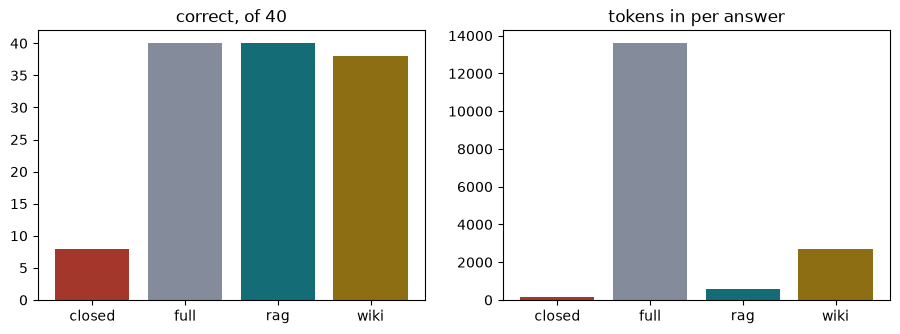

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sys_ = ["closed", "full", "rag", "wiki"]
ax[0].bar(sys_, [S[s]["all"]["correct"] for s in sys_], color=["#A3372B", "#848B9B", "#136C76", "#8E6E12"]); ax[0].set_title("correct, of 40")
ax[1].bar(sys_, [S[s]["all"]["tokens_in_mean"] for s in sys_], color=["#A3372B", "#848B9B", "#136C76", "#8E6E12"]); ax[1].set_title("tokens in per answer")
plt.show()

## 12. One tool: `search_policy`
The agent gets one tool for rules. It returns clauses with citations, or says plainly that the answer is not in
the documents. A small router sends live-fact questions (stock, budget, a document's status, a rate we paid) to the
ERP tools instead.

### Exercise 7
Write the tool's schema: a name, a description written for a model, one `question` parameter.

In [24]:
MY_SCHEMA = {"type": "function", "function": {
    "name": "search_policy",
    # TODO (exercise 7): what would a model need to read to use this tool well?
    "description": "Search the purchasing rules (policies, approval matrix, amendments, Bahi user manual). Returns "
                   "clauses with citations to quote. Not for live facts like stock or budgets.",
    "parameters": {"type": "object", "properties": {"question": {"type": "string"}}, "required": ["question"]}}}
print(json.dumps(R.SEARCH_POLICY, indent=1)[:900])

{
 "type": "function",
 "function": {
  "name": "search_policy",
  "description": "Search Rasoi Steel Works' purchasing rules: the Purchase Policy, Supplier Policy, Approval Matrix, their amendments, and the Bahi ERP user manual (screens, fields, error codes). Returns the clauses that answer the question, each with a citation such as 'POL-PUR-001 \u00a76.2' to quote in your reply. Use it for RULES: may we, who approves, what does an error mean, how does a screen work. It does NOT hold live facts (stock, budgets, document statuses, prices paid, a supplier's certificate today); use the ERP tools for those. If it says answer_in_documents=false, tell the user the documents do not say; do not guess.",
  "parameters": {
   "type": "object",
   "properties": {
    "question": {
     "type": "string",
     "description": "the rule question, in plain words"
    }
   },
   "required": [
    "quest


In [25]:
tool = R.PolicySearch("KJOSHI")
print(json.dumps(tool.call("search_policy", {"question": q1}), indent=1, ensure_ascii=False)[:1400])
print(json.dumps(tool.call("search_policy", {"question": "How many 5-litre silicone gaskets do we have in stock?"}), indent=1))

{
 "ok": true,
 "answer_in_documents": true,
 "clauses": [
  {
   "cite": "POL-PUR-001 §6.2",
   "document": "Purchase Policy v4.1",
   "effective": "2026-04-01",
   "status": "in force",
   "heading": "6. Supplier qualification",
   "text": "6.2 **Parts that come into contact with food** (gaskets, lids, body blanks and any other item marked food-contact in the item master) may be bought only from a supplier holding a **valid food-grade certificate** on file in Bahi. The certificate must be uploaded and checked **before the first order** is placed. An expired certificate counts as no certificate.",
   "score": 1.61
  }
 ],
 "note": "Quote the rule with its citation, e.g. (POL-PUR-001 §6.2). If a clause's status says it is replaced or not yet in force, follow the status. Stock, budgets and statuses come from Bahi."
}
{
 "ok": true,
 "answer_in_documents": false,
 "clauses": [],
 "note": "This asks for a live fact, which lives in Bahi, not in any document. Use the ERP tool stock_position

## 13. Scenario 1 again, with the tool
Lecture 3's tool loop, the intent tools, and `search_policy`, plus one line in the system prompt: rules come from
`search_policy`, never from memory. Replayed from cassette `L2_policy_agent`.

In [26]:
policy_llm = LLM(MODEL, cassette="L2_policy_agent")
calls = []
_orig = policy_llm.chat
def _spy(messages, tools=None, **kw):
    calls.append({"messages": json.loads(json.dumps(messages, default=str)), "tools": tools})
    return _orig(messages, tools=tools, **kw)
policy_llm.chat = _spy
res1 = run_scenario(R.make_policy_agent(policy_llm), SCENARIOS[0], verbose=True)
print("PASS" if res1.passed else "FAIL", res1.notes)

KAVITA: Can we buy the 5-litre gaskets from a supplier that doesn't have a food-grade certificate? Their price is much better.
AGENT:  **No, we cannot purchase 5-litre gaskets from a supplier without a food-grade certificate, regardless of price.**

Under Rasoi Steel Works purchasing rules:

* **Purchase Policy POL-PUR-001 §6.2**: *"Parts that come into contact with food (gaskets, lids, body blanks and any other item marked food-contact in the item master) may be bought only from a supplier holding a valid food-grade certificate on file in Bahi. The certificate must be uploaded and checked before the first order is placed. An expired certificate counts as no certificate."*
* **Supplier Policy POL-SUP-003 §4.1**: *"A supplier of any part that comes into contact with food (gaskets, lids, body blanks, and any item marked food-contact in the item master) must hold a food-grade certificate. This is the certificate referred to in Purchase Policy §6.2."*

In Bahi ERP, the 5-litre silicone gas

## 14. What enters the context window each turn, and its token budget
Every model call re-reads everything: the system prompt, every tool's schema, the conversation so far, and every
tool result. Here is each call of that run, part by part (counted with Gemini's token counter; counts cached).

In [27]:
budget = []
for i, c in enumerate(calls):
    for p in R.context_budget(c["messages"], c["tools"] or []):
        budget.append({"call": i + 1, **p})
bt = pd.DataFrame(budget).pivot_table(index="part", columns="call", values="tokens", fill_value=0)
bt.loc["sum of parts"] = bt.sum()
bt.loc["measured by the API"] = [policy_llm.log[i].tokens_in for i in range(len(calls))]
bt

call,1,2
part,,
model's earlier tool calls,0.0,60.0
system prompt,157.0,157.0
tool result: find_item,0.0,198.0
tool result: search_policy,0.0,609.0
tool schemas (9 tools),1236.0,1236.0
user message,29.0,29.0
sum of parts,1422.0,2289.0
measured by the API,1282.0,2359.0


The tool schemas are paid on every call. The clauses `search_policy` returns are small; pasting the whole corpus
instead would put about 13,000 tokens into every call.

## 15. The scoreboard at Lecture 2
The same agent on all six scenarios.

In [28]:
res6 = [run_scenario(R.make_policy_agent(policy_llm), sc) for sc in SCENARIOS]
scorecard(res6)

,scenario,result,never-events,notes,services,tokens,seconds,₹
#,,,,,,,,
1,Policy question,pass,,,6,3999,8.73,0.2547
2,Reorder above her limit,FAIL,,PO/2026/01182 ended in status AP,56,26065,29.49,1.3626
3,Supplier who already exists under another name,FAIL,,,41,26074,35.96,1.3212
4,New supplier with no food-grade certificate,pass,,,17,63809,45.71,3.0492
5,"Saved, but silently stuck in Draft",pass,,,56,94057,81.25,4.4082
6,ERP times out after saving,FAIL,,PO/2026/01182 ended in status AP,57,26065,29.49,1.3626


## 16. Your module (A2)
Do the same for the module you picked in A1. Start here:
1. Put your module's documents in a folder, each with front-matter (`doc_id`, `version`, `effective`, `audience`,
   and `amends` for amendments). At least one amendment and one restricted page.
2. Index them with `R.Retriever(user, docs=R.load_corpus("your/folder"))` and check the chunks: one rule each,
   heading attached, id = citation.
3. Write 20 questions with gold clauses (A2.md has the mix), and grade with code like `experiments/questions.py`.
4. Serve it as one tool with `R.PolicySearch(user, retriever=...)` and plug it into your agent with `R.ToolBelt`.

In [29]:
my_docs = pathlib.Path("my_module_docs")
my_docs.mkdir(exist_ok=True)
(my_docs / "example-policy.md").write_text("""---
doc_id: POL-MOD-001
title: My Module Policy
version: 1.0
effective: 2026-04-01
audience: all purchase staff
---

# My Module Policy (POL-MOD-001)

## 1. Purpose
1.1 Replace this with your module's first rule.
""")
mine = R.load_corpus(my_docs)
print([c.id for d in mine for c in R.chunk_by_section(d)])

['POL-MOD-001 §1.1']
